## Exploratory Data Analysis

This file performs EDA, as per the project doc's reccomendations. Comments help understand code, while inferences about the results are detailed in the report.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Load dataset and make a copy to perform EDA on
df = pd.read_csv("../data/dataset.csv")
df1 = df.copy()

print("Dataset Shape:", df1.shape)
print(f"Number of countries: {df1.shape[0]} | Number of columns: {df1.shape[1]}\n")
df1.info()

Dataset Shape: (195, 14)
Number of countries: 195 | Number of columns: 14

<class 'pandas.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Country                         195 non-null    str    
 1   Region                          195 non-null    str    
 2   Level                           193 non-null    float64
 3   Agriculture                     187 non-null    float64
 4   Industry                        188 non-null    float64
 5   Services                        187 non-null    float64
 6   Dominant_Sector                 187 non-null    str    
 7   Access_to_electricity           195 non-null    float64
 8   Inflation_consumer_prices       181 non-null    float64
 9   Individuals_using_the_Internet  189 non-null    float64
 10  Trade                           171 non-null    float64
 11  GDP_Growth                      1

In [15]:
#First 5 rows along with a check for duplicates
display(df1.head(5))
print(f'\nDuplicate Rows: {df1.duplicated().sum()}')

#Summary Statistics and Target Class Counts
print("\nSummary Statistics")
display(df1.describe().T)
print("\nTarget Class Counts")
class_counts = pd.DataFrame({'Count': df1['Level'].value_counts(dropna=False).sort_index(),
                             'Percentage': (df1['Level'].value_counts(normalize=True, dropna=False).sort_index()*100).round(2)
                             })

display(class_counts)

,Country,Region,Level,Agriculture,Industry,Services,Dominant_Sector,Access_to_electricity,Inflation_consumer_prices,Individuals_using_the_Internet,Trade,GDP_Growth,Unemployment_total,Infant_mortality
0,AFG,MEA,0.0,34.743247,13.449823,51.806930,Services,85.3,-4.644709,15.928400,66.999578,2.266944,14.008,49.9
1,ALB,ECS,2.0,16.274239,23.160712,60.565049,Services,100.0,4.758346,83.135592,82.352493,4.015417,10.669,8.3
2,DZA,MEA,1.0,13.369245,37.547655,49.083100,Services,100.0,9.322174,76.197601,43.739798,4.100000,11.645,19.7
3,AND,ECS,2.0,0.478492,12.428226,87.093282,Services,100.0,NaN,94.214996,NaN,2.583555,NaN,2.5
4,AGO,SSF,1.0,20.909337,35.701247,43.389416,Services,51.1,13.644102,37.885899,53.607013,1.320166,14.051,33.0



Duplicate Rows: 0

Summary Statistics


,count,mean,std,min,25%,50%,75%,max
Level,193.0,1.248705,0.677242,0.000000,1.000000,1.000000,2.000000,2.000000
Agriculture,187.0,10.344884,10.309467,0.015094,2.373346,6.661449,17.019030,43.988089
Industry,188.0,25.987924,11.930156,2.086302,18.110622,24.531309,31.280318,78.899528
Services,187.0,63.589729,14.381941,19.331194,53.127794,64.658763,74.939407,96.947243
Access_to_electricity,195.0,86.969744,23.219572,5.400000,84.450000,100.000000,100.000000,100.000000
Inflation_consumer_prices,181.0,11.425775,23.650974,-4.644709,3.597456,5.869104,9.328996,221.341644
Individuals_using_the_Internet,189.0,69.764455,26.443522,6.671000,51.200000,79.996630,90.600000,100.000000
Trade,171.0,94.057923,60.950272,2.473729,51.617171,81.962548,115.979792,402.566968
GDP_Growth,191.0,2.942318,4.599120,-29.433272,1.129311,3.133903,4.960761,33.795011
Unemployment_total,180.0,6.866522,5.697213,0.130000,3.163500,5.181000,8.427500,34.610000



Target Class Counts


,Count,Percentage
Level,,
0.0,26,13.33
1.0,93,47.69
2.0,74,37.95
NaN,2,1.03


### Dataset Overview

- The dataset covers **195 countries** across **14 columns**, including 10 numerical predictors, 2 categorical predictors, 1 country identifier, and the target variable `Level`.
- The target variable `Level` is not evenly distributed: 1.0 accounts for 47.69% (93 countries), 2.0 for 37.95% (74), and 0.0 for 13.33% (26). There are also 2 missing target labels, which need to be removed before supervised modelling.
- `Agriculture`, `Industry`, and `Services` represent the percentage shares of GDP contributed by each sector and add up to roughly 100% for each country. `Dominant_Sector` is derived from these shares, so including all of them together could introduce redundancy.
- The features have noticeably different scales. While `Access_to_electricity` and `Individuals_using_the_Internet` are bounded between 0 and 100%, `Trade` reaches 402.56% and `Inflation_consumer_prices` ranges from -4.64% to 221.34%.


Missing Values by Feature


,Missing Count,Percentage
Trade,24,12.31
Unemployment_total,15,7.69
Inflation_consumer_prices,14,7.18
Dominant_Sector,8,4.10
Services,8,4.10
Agriculture,8,4.10
Industry,7,3.59
Individuals_using_the_Internet,6,3.08
GDP_Growth,4,2.05
Level,2,1.03


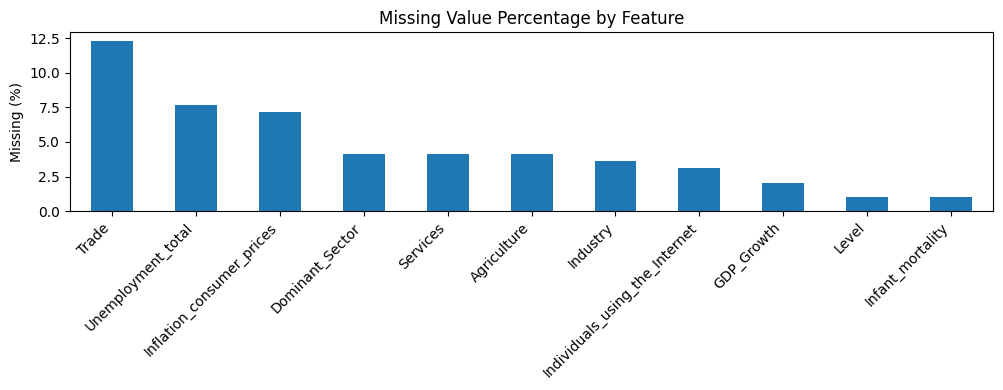

Level,0.0,1.0,2.0
Region,0.0,0.0,0.0
Agriculture,11.5,3.2,0.0
Industry,11.5,3.2,0.0
Services,11.5,3.2,0.0
Dominant_Sector,11.5,3.2,0.0
Access_to_electricity,0.0,0.0,0.0
Inflation_consumer_prices,15.4,6.5,2.7
Individuals_using_the_Internet,3.8,4.3,0.0
Trade,15.4,14.0,6.8
GDP_Growth,7.7,0.0,1.4


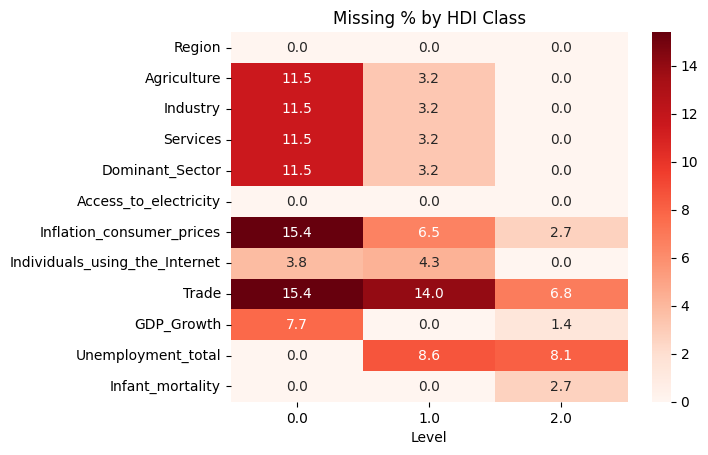

In [16]:
# Missing Value Breakdown
print("\nMissing Values by Feature")
missing_summary = pd.DataFrame({
    'Missing Count': df1.isnull().sum(),
    'Percentage': (df1.isnull().sum() / len(df1) * 100).round(2)
}).sort_values(by='Percentage', ascending=False)
display(missing_summary)

#Visualize missingness
missing_nonzero = missing_summary[missing_summary['Missing Count'] > 0]
if not missing_nonzero.empty:
    plt.figure(figsize=(10, 4))
    missing_nonzero['Percentage'].plot(kind='bar')
    plt.title("Missing Value Percentage by Feature")
    plt.ylabel("Missing (%)")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

#Missingness by HDI Target Class
feature_cols = []
for c in df1.columns:
    if c not in ['Level', 'Country']:
        feature_cols.append(c)
missing_by_class = (df1[feature_cols].isnull().groupby(df1['Level']).mean()*100).T.round(1)
display(missing_by_class)
sns.heatmap(missing_by_class, annot=True, fmt='.1f', cmap='Reds')
plt.title('Missing % by HDI Class')
plt.show()

### Missing Value Patterns

- `Region` and `Access_to_electricity` have no missing values across all 195 countries.
- Among the remaining features, `Trade` has the highest missing rate at 12.31% (24 countries), followed by `Unemployment_total` at 7.69% (15), `Inflation_consumer_prices` at 7.18% (14), and the sector share columns (`Agriculture`, `Services`, `Dominant_Sector`) at 4.10% (8).

- Missingness varies noticeably across HDI classes:
  - In Class 0, `Inflation_consumer_prices` and `Trade` are each missing in 15.4% of countries (compared to 2.7% and 6.8% in Class 2), sector shares are missing in 11.5% (vs. 3.2% in Class 1 and 0% in Class 2), and `GDP_Growth` is missing in 7.7% (vs. 0% in Class 1 and 1.4% in Class 2).
  - `Individuals_using_the_Internet` has small gaps in Class 0 (3.8%) and Class 1 (4.3%), and none in Class 2.
  - `Unemployment_total` goes the other way, missing in 8.6% of Class 1 and 8.1% of Class 2 countries, but 0% of Class 0.
  
- Since missingness rates differ across HDI tiers rather than occurring completely at random, keeping missingness indicator flags alongside median imputation helps preserve that pattern for modeling.

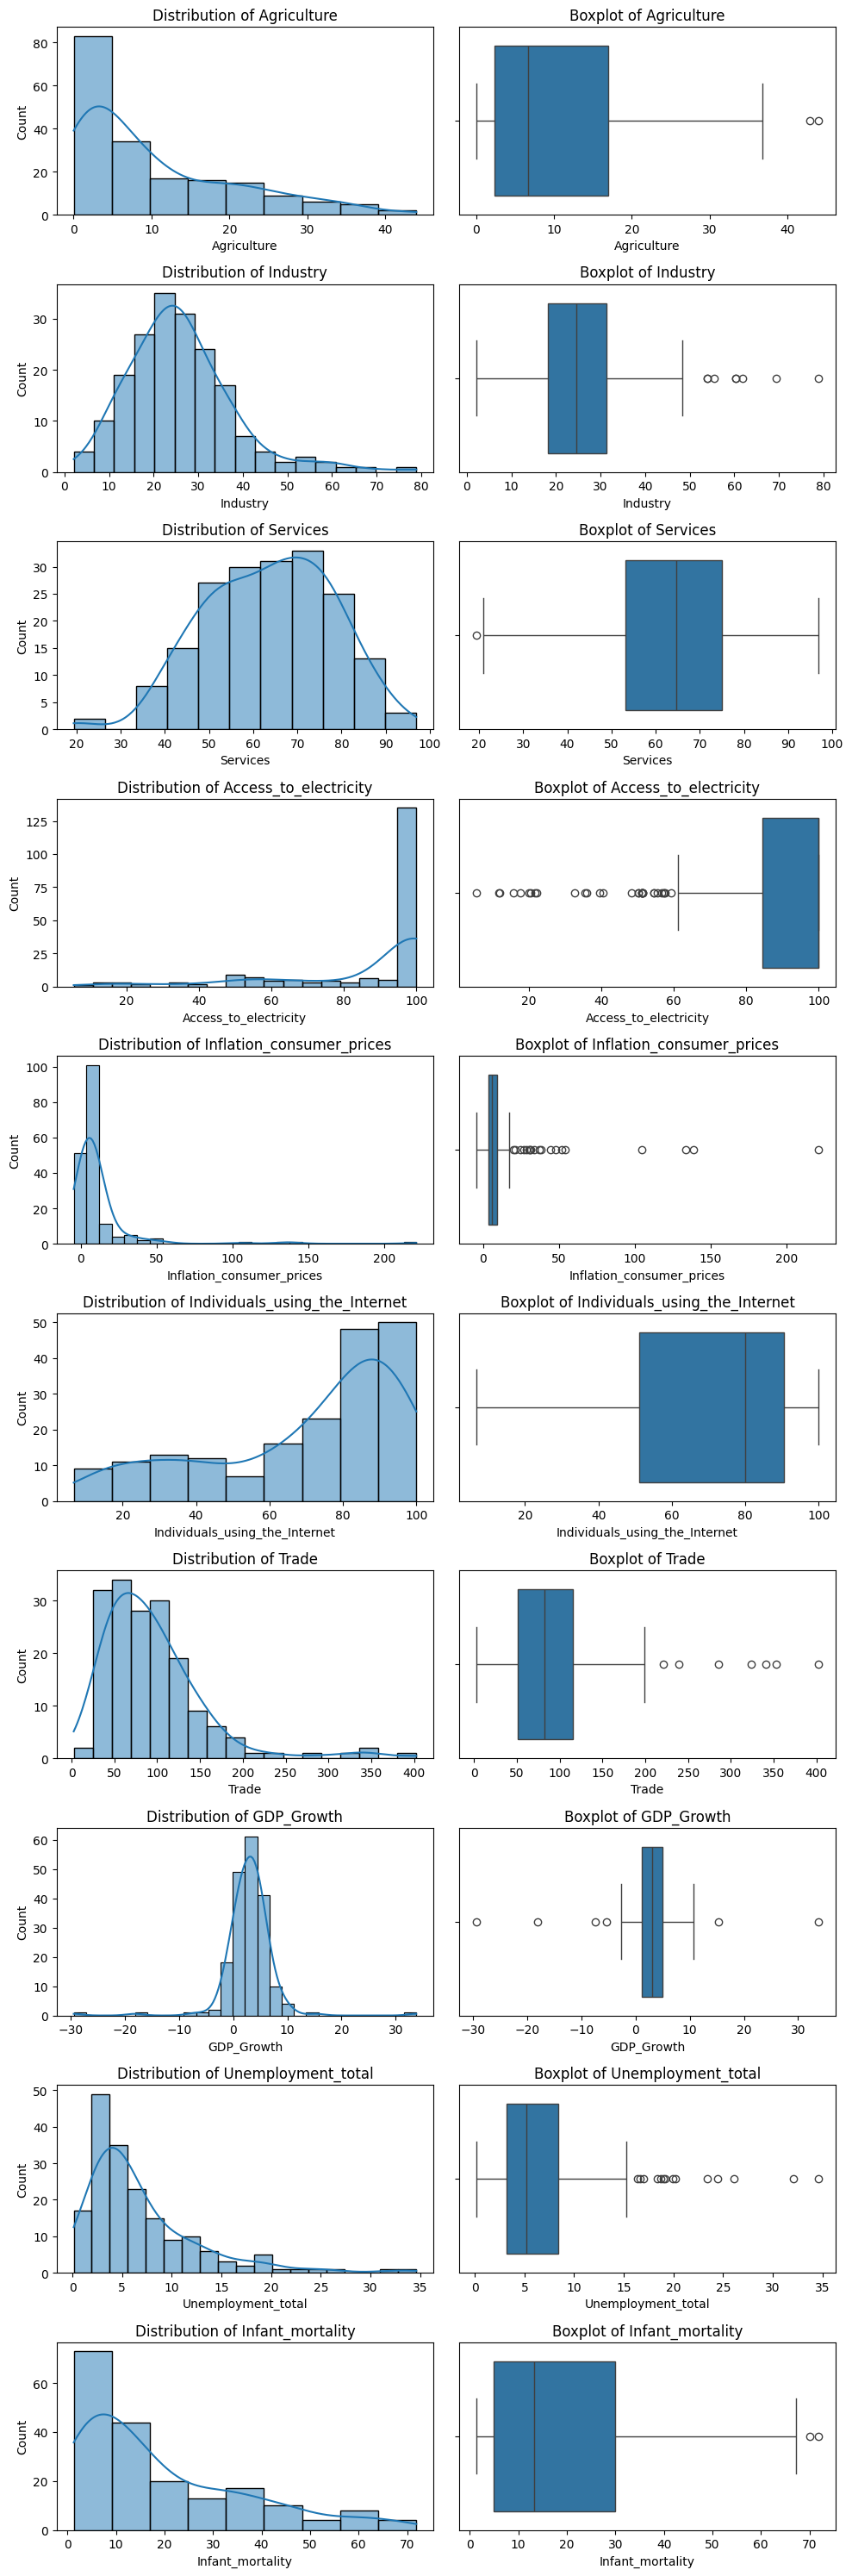

,feature,mean,median,n_outliers,examples
0,Agriculture,10.34,6.66,2,"[NER, SYR]"
1,Industry,25.99,24.53,8,"[BRN, GAB, GUY, IRQ, KWT]"
2,Services,63.59,64.66,1,[LBY]
3,Access_to_electricity,86.97,100.00,31,"[AGO, BEN, BFA, BDI, CAF]"
4,Inflation_consumer_prices,11.43,5.87,19,"[ARG, BDI, EGY, ETH, GHA]"
5,Individuals_using_the_Internet,69.76,80.00,0,[]
6,Trade,94.06,81.96,7,"[DJI, HKG, IRL, LUX, MLT]"
7,GDP_Growth,2.94,3.13,6,"[GNQ, GUY, MHL, WSM, SDN]"
8,Unemployment_total,6.87,5.18,14,"[BWA, COG, DJI, SWZ, GAB]"
9,Infant_mortality,19.24,13.20,2,"[NGA, SSD]"


In [17]:
num_cols = []
for c in feature_cols:
    if c not in ['Region', 'Dominant_Sector']:
        num_cols.append(c)
plt.figure(figsize=(10, 3*len(num_cols)))
for i, col in enumerate(num_cols):
    plt.subplot(len(num_cols), 2, 2*i+1)
    sns.histplot(df1[col], kde=True)
    plt.title(f'Distribution of {col}')

    plt.subplot(len(num_cols), 2, 2*i+2)
    sns.boxplot(x=df1[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

rows = []
for c in num_cols:
    q1, q3 = df1[c].quantile(0.25), df1[c].quantile(0.75)
    iqr = q3 - q1
    out = df1[(df1[c] < q1 - 1.5*iqr) | (df1[c] > q3 + 1.5*iqr)]
    rows.append((c, df1[c].mean(), df1[c].median(), len(out), list(out['Country'][:5])))
display(pd.DataFrame(rows, columns=['feature', 'mean', 'median', 'n_outliers', 'examples']).round(2))

### Numerical Distributions & Outliers

- `Inflation_consumer_prices` (19 upper outliers, up to 221.3%), `Unemployment_total` (14 upper outliers, up to 34.6%), `Trade` (7 upper outliers, up to 402.6%), `Infant_mortality` (2 upper outliers, up to 71.9), and `Agriculture` (2 upper outliers, up to 44.0%) are all right-skewed.

- `Access_to_electricity` clusters at the 100% ceiling, leaving 31 lower-tail outliers (down to 5.4%). `Individuals_using_the_Internet` is also left-skewed around a median of 80.0%, though its wide IQR leaves 0 IQR outliers.

- `Services` is roughly symmetric around a median of 64.7% with 1 lower outlier (`LBY` at 19.3%). `Industry` has a median of 24.5% with 8 upper outliers (up to 78.9%), and `GDP_Growth` is concentrated around its median of 3.1% with 6 two-sided outliers ranging from -29.4% to +33.8%.

- All values fall within plausible ranges (no negative sector shares or invalid percentages). The extreme values correspond to real economic cases (such as high-inflation episodes or small trade-heavy economies) rather than data errors, so we keep all rows and rely on scaling during preprocessing.


Agriculture by HDI Class


,Level,mean,median,std
0,0.0,27.359632,28.869380,9.144725
1,1.0,12.368123,10.260457,8.208363
2,2.0,2.595821,2.131456,2.516206



Industry by HDI Class


,Level,mean,median,std
0,0.0,22.453120,22.888648,5.991569
1,1.0,27.088806,26.307800,13.185007
2,2.0,25.943419,23.694701,11.555162



Services by HDI Class


,Level,mean,median,std
0,0.0,50.187248,50.121636,10.106157
1,1.0,60.543072,59.553625,13.740412
2,2.0,71.460760,72.835945,11.628312


... (10 outputs left out)


Unemployment_total by HDI Class


,Level,mean,median,std
0,0.0,6.514385,4.739,6.220255
1,1.0,7.956506,5.407,6.928013
2,2.0,5.688735,5.224,2.994608



Infant_mortality by HDI Class


,Level,mean,median,std
0,0.0,48.330769,45.7,12.492710
1,1.0,22.259140,17.7,12.976678
2,2.0,5.138889,4.0,3.452844


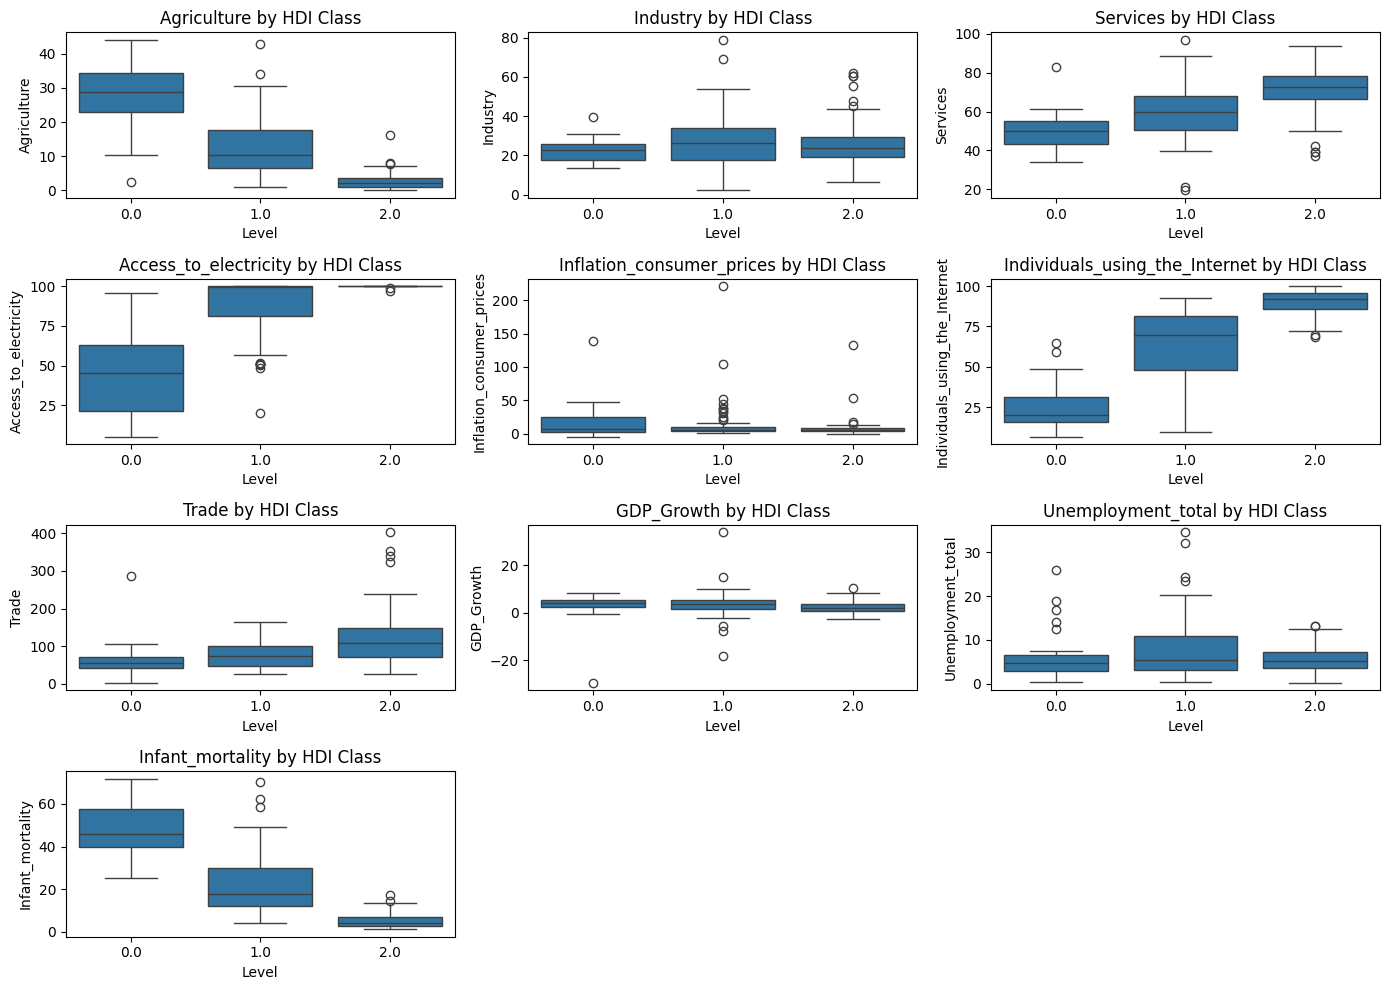

,Agriculture,Industry,Services,Access_to_electricity,Inflation_consumer_prices,Individuals_using_the_Internet,Trade,GDP_Growth,Unemployment_total,Infant_mortality
Agriculture,1.000000,-0.168539,-0.577209,-0.657656,0.104886,-0.817615,-0.428551,0.044254,-0.139949,0.722332
Industry,-0.168539,1.000000,-0.707633,-0.007196,-0.092176,0.123189,-0.053068,0.105843,0.021864,0.011045
Services,-0.577209,-0.707633,1.000000,0.474445,0.001233,0.474891,0.360973,-0.122388,0.082887,-0.525054
Access_to_electricity,-0.657656,-0.007196,0.474445,1.000000,-0.068049,0.823468,0.246288,-0.068236,-0.017162,-0.787203
Inflation_consumer_prices,0.104886,-0.092176,0.001233,-0.068049,1.000000,-0.063289,-0.177964,-0.283606,0.028716,0.134394
Individuals_using_the_Internet,-0.817615,0.123189,0.474891,0.823468,-0.063289,1.000000,0.400344,-0.098945,-0.023373,-0.826155
Trade,-0.428551,-0.053068,0.360973,0.246288,-0.177964,0.400344,1.000000,0.033622,0.026404,-0.334630
GDP_Growth,0.044254,0.105843,-0.122388,-0.068236,-0.283606,-0.098945,0.033622,1.000000,0.035746,0.059653
Unemployment_total,-0.139949,0.021864,0.082887,-0.017162,0.028716,-0.023373,0.026404,0.035746,1.000000,0.142490
Infant_mortality,0.722332,0.011045,-0.525054,-0.787203,0.134394,-0.826155,-0.334630,0.059653,0.142490,1.000000


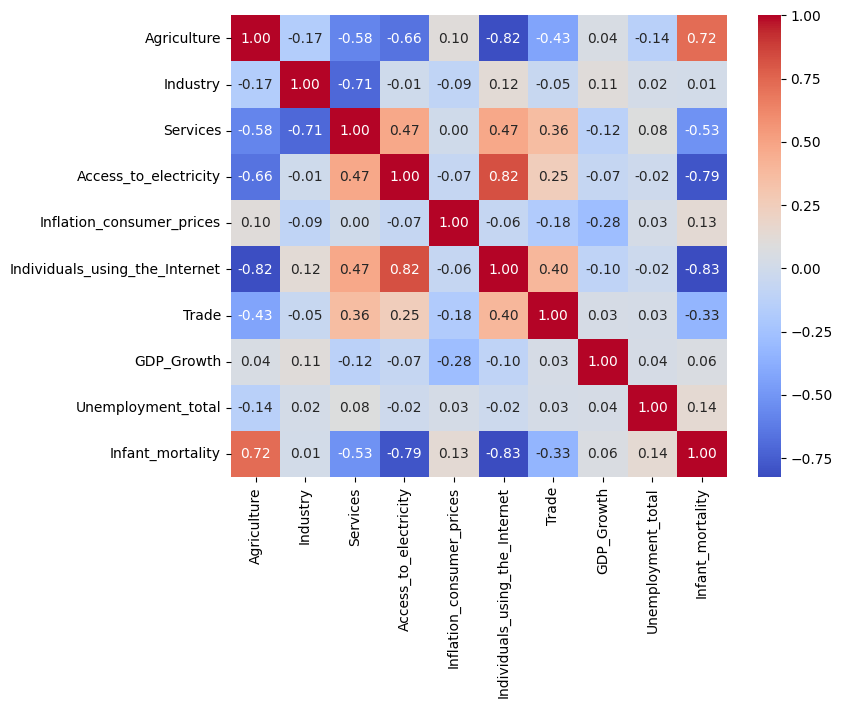

Agriculture vs Individuals_using_the_Internet: r = -0.82
Agriculture vs Infant_mortality: r = 0.72
Industry vs Services: r = -0.71
Access_to_electricity vs Individuals_using_the_Internet: r = 0.82
Access_to_electricity vs Infant_mortality: r = -0.79
Individuals_using_the_Internet vs Infant_mortality: r = -0.83


In [18]:
for col in num_cols:
    print(f"\n{col} by HDI Class")
    display(df1.groupby('Level')[col].agg(['mean', 'median', 'std']).reset_index())

plt.figure(figsize=(14, 10))
for i, col in enumerate(num_cols):
    plt.subplot(4, 3, i+1)
    sns.boxplot(data=df1, x='Level', y=col)
    plt.title(f'{col} by HDI Class')
plt.tight_layout()
plt.show()

corr = df1[num_cols].corr()
display(corr)

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

for i, a in enumerate(num_cols):
    for b in num_cols[i+1:]:
        if abs(corr.loc[a, b]) > 0.7:
            print(f"{a} vs {b}: r = {corr.loc[a, b]:.2f}")

### Patterns Across HDI Classes & Feature Correlations

- Several indicators separate the three HDI classes clearly:
  - `Individuals_using_the_Internet` (medians: 19.9% → 69.4% → 92.2%) and `Infant_mortality` (45.7 → 17.7 → 4.0) move consistently across tiers.
  - `Agriculture` drops sharply as HDI rises (28.9% → 10.3% → 2.1%), while `Services` (50.1% → 59.6% → 72.8%), `Access_to_electricity` (45.4% → 99.3% → 100.0%), and `Trade` (55.7% → 75.0% → 107.3%) increase across classes.
- `Industry`, `Inflation_consumer_prices`, `Unemployment_total`, and `GDP_Growth` overlap heavily across classes, differing mostly in spread and extreme values.

- Among numerical predictors, six pairs have strong linear correlations ($|r| > 0.7$):
  - `Individuals_using_the_Internet` correlates negatively with `Infant_mortality` ($r = -0.83$) and `Agriculture` ($r = -0.82$), and positively with `Access_to_electricity` ($r = 0.82$).
  - `Access_to_electricity` and `Infant_mortality` correlate negatively ($r = -0.79$), while `Agriculture` and `Infant_mortality` correlate positively ($r = 0.72$).
  - `Industry` and `Services` correlate negatively ($r = -0.71$), which makes sense given that sector shares sum to 100% of GDP.
  
- `Inflation_consumer_prices`, `GDP_Growth`, and `Unemployment_total` show very weak linear relationships with the rest of the features (all $|r| \le 0.28$, and below $0.20$ outside of `GDP_Growth` vs. `Inflation_consumer_prices` at $r = -0.28$).

Region
ECS    52
SSF    48
LCN    33
EAS    31
MEA    23
SAS     6
NAC     2
Name: count, dtype: int64

Level,0.0,1.0,2.0,All
Region,,,,
EAS,0,22,8,30
ECS,0,7,44,51
LCN,0,23,10,33
MEA,4,11,8,23
NAC,0,0,2,2
SAS,0,6,0,6
SSF,22,24,2,48
All,26,93,74,193


Level,0.0,1.0,2.0
Region,,,
EAS,0.000,0.733,0.267
ECS,0.000,0.137,0.863
LCN,0.000,0.697,0.303
MEA,0.174,0.478,0.348
NAC,0.000,0.000,1.000
SAS,0.000,1.000,0.000
SSF,0.458,0.500,0.042


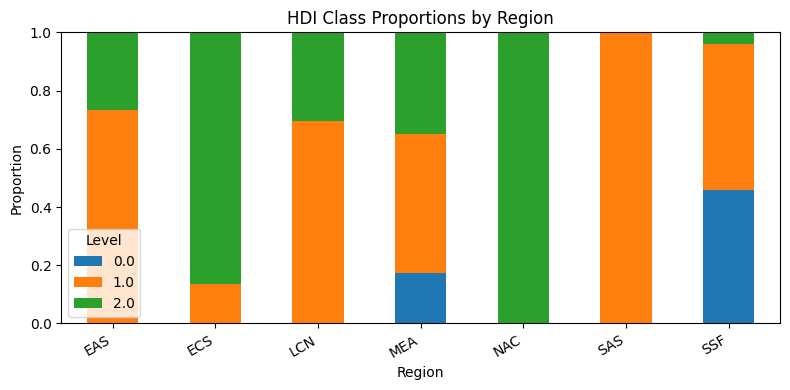

Dominant_Sector
Services       177
Industry         8
NaN              8
Agriculture      2
Name: count, dtype: int64

Level,0.0,1.0,2.0,All
Dominant_Sector,,,,
Agriculture,2,0,0,2
Industry,0,4,4,8
Missing,3,3,0,6
Services,21,86,70,177
All,26,93,74,193


Level,0.0,1.0,2.0
Dominant_Sector,,,
Agriculture,1.000,0.000,0.000
Industry,0.000,0.500,0.500
Missing,0.500,0.500,0.000
Services,0.119,0.486,0.395


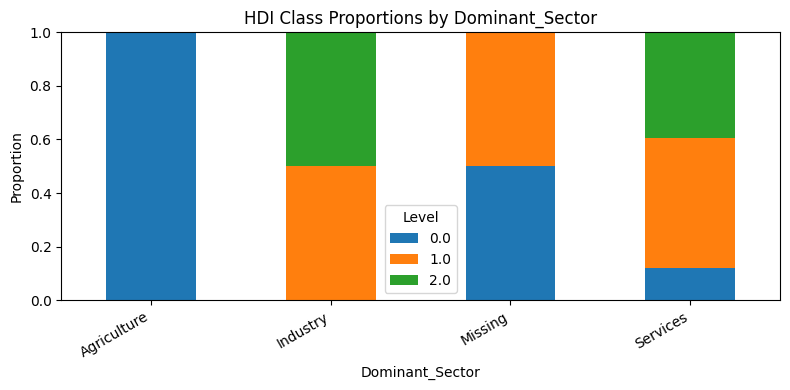

In [19]:
cat = ['Region', 'Dominant_Sector']
for col in cat:
    display(df1[col].value_counts(dropna=False))
    df2=pd.crosstab(df1[col].fillna('Missing'), df1['Level'], margins=True)
    display(df2)

    df3=pd.crosstab(df1[col].fillna('Missing'), df1['Level'], normalize='index')
    display(df3.round(3))

    df3.plot(kind='bar', stacked=True, figsize=(8, 4))
    plt.title(f'HDI Class Proportions by {col}')
    plt.ylabel('Proportion')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

### Categorical Feature Analysis

**Region:** Every labelled country has a valid World Bank region code (0 missing), and HDI classes split clearly across regions. `EAS` (73.3% Class 1), `LCN` (69.7% Class 1), and `SAS` (100.0% Class 1) are mostly Class 1 with no Class 0 countries, while `ECS` (86.3% Class 2) and `NAC` (100.0% Class 2) are heavily concentrated in Class 2. `MEA` is spread across all three tiers (17.4% Class 0, 47.8% Class 1, 34.8% Class 2), whereas `SSF` accounts for 22 of the 26 Class 0 countries overall (45.8% Class 0, 50.0% Class 1, 4.2% Class 2).

**Dominant Sector:** Services is the dominant sector in 177 out of 193 labelled countries, with Class 1 making up the largest share (48.6%, compared to 39.5% Class 2 and 11.9% Class 0). All 8 countries where Industry is dominant split evenly between Class 1 (4) and Class 2 (4), both Agriculture-dominant countries fall in Class 0 (2), and the 6 labelled countries with missing sector shares split evenly between Class 0 (3) and Class 1 (3). Because the Non-Services groups have very small counts, their proportions are best read alongside the continuous sector-share columns.